# Fase 1 - Factores asociados al acceso educativo en Paraguay y diferencias según departamento.

# Librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga de datos

In [2]:

# Leer el archivo, intentando con delimitador de punto y coma y codificación latin1
df = pd.read_csv('https://drive.google.com/uc?export=download&id=1AbvSxPP-BIMmy9CgfiUTA7q_M8nSM8Ax', sep=';')

df_new = df[['L02','UPM', 'NVIVI', 'NHOGA','DPTO', 'P02', 'ED0504', 'ED06C', 'ED08', 'ED09', 'ED10', 'añoest']].copy()


/tmp/ipykernel_104992/2378078733.py:2: DtypeWarning: Columns (192,199) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('https://drive.google.com/uc?export=download&id=1AbvSxPP-BIMmy9CgfiUTA7q_M8nSM8Ax', sep=';')


# Analisis inicial (antes de limpiar)

In [3]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55934 entries, 0 to 55933
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   L02     55934 non-null  int64 
 1   UPM     55934 non-null  int64 
 2   NVIVI   55934 non-null  int64 
 3   NHOGA   55934 non-null  int64 
 4   DPTO    55934 non-null  int64 
 5   P02     55934 non-null  int64 
 6   ED0504  55934 non-null  object
 7   ED06C   55934 non-null  object
 8   ED08    55934 non-null  object
 9   ED09    55934 non-null  object
 10  ED10    55934 non-null  object
 11  añoest  55934 non-null  object
dtypes: int64(6), object(6)
memory usage: 5.1+ MB


Las variables ED0504, ED06C, ED08, ED09, ED10 y añoest pueden ser tratadas y analizadas de manera similar por ser de tipo String (Object), ademas que conocemos sus respectivos codigos especiales por el diccionario provehido por la INE.

In [4]:
n0 = len(df_new)

variables_info = []
codigo_especial = {
    "ED0504": ["9999", "8888"],
    "ED06C" : ["99"],
    "ED08": ["99"],
    "ED09": ["9"],
    "ED10": ["99"],
    "añoest": ["99"],
}

for variable in ["ED0504", "ED06C", "ED08", "ED09", "ED10", "añoest"]:
    serie = df_new[variable]

    cant_blanco = (serie.fillna("").str.strip() == "").sum()
    cant_especiales = serie.isin(codigo_especial.get(variable, [])).sum()
    val_unicos = serie.nunique(dropna=False)

    variables_info.append({
        "variable": variable,
        "valores_unicos": val_unicos,
        "cantidad_en_blanco": cant_blanco,
        "porcent_en_blanco": round((cant_blanco / n0) * 100, 2),
        "cantidad_NR": cant_especiales,
        "porcent_NR": round((cant_especiales / n0) * 100, 2),
        "porcent_faltante_total": round(((cant_blanco + cant_especiales) / n0) * 100, 2),
    })

Las variables DPTO y P02 las tratamos y analizamos de una manera distinta respecto a las anteriores por ser ambas del tipo int64, ademas estas carecen de codigos especiales.

In [5]:
df_new['DPTO'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

In [6]:
df_new['P02'].unique()

array([ 65,  69,  78,  40,  39,  19,  32,  34,  24,  27,  63,  71,  76,
        46,  42,  31,  26,  10,  80,  48,  23,  61,  36,  29,  12,   7,
         4,   3,  28,  70,  75,  60,  21,  56,   5,   8,  43,  22,  16,
        11,  20,  18,  55,  73,  57,   6,  14,   2,  33,  59,  30,  15,
        44,  51,  67,  37,   9,  53,   1,  68,  66,  50,  35,  17,  49,
        45,  13,  25,  52,  74,  86,  62,  41,   0,  90,  85,  47,  38,
        72,  58,  64,  79,  88,  94,  97,  84,  82,  83,  54,  81,  93,
        91,  77,  98,  92,  87,  89,  95,  96, 103, 104, 101, 100,  99,
       102, 106])

Las edades > 99 contenidas en la variable P02 las trataremos como outliers mas adelante.

In [7]:
for variable in ["DPTO", "P02", "L02"]:
    serie = df_new[variable]

    cant_blanco = serie.isna().sum()
    cant_especiales = 0
    val_unicos = serie.nunique(dropna=False)

    variables_info.append({
        "variable": variable,
        "valores_unicos": val_unicos,
        "cantidad_en_blanco": cant_blanco,
        "porcent_en_blanco": round((cant_blanco / n0) * 100, 2),
        "cantidad_NR": cant_especiales,
        "porcent_NR": round((cant_especiales / n0) * 100, 2),
        "porcent_faltante_total": round(((cant_blanco + cant_especiales) / n0) * 100, 2),
    })
df_variables_info = pd.DataFrame(variables_info)

# Con esta linea exportas a csv
# df_variables_info.to_csv("variables-info.csv", index=False)
df_variables_info

,variable,valores_unicos,cantidad_en_blanco,porcent_en_blanco,cantidad_NR,porcent_NR,porcent_faltante_total
0,ED0504,83,4056,7.25,17,0.03,7.28
1,ED06C,15,45694,81.69,17,0.03,81.72
2,ED08,19,17042,30.47,13,0.02,30.49
3,ED09,5,39519,70.65,13,0.02,70.68
4,ED10,20,31510,56.33,15,0.03,56.36
5,añoest,21,3221,5.76,17,0.03,5.79
6,DPTO,16,0,0.00,0,0.00,0.00
7,P02,106,0,0.00,0,0.00,0.00
8,L02,26,0,0.00,0,0.00,0.00


# Limpieza y transformacion

Como todas nuestras variables contienen codigos numericos a continuacion se realiza la conversion al tipo Int64.

In [8]:
# 3.1 Tipos numericos base
for variable in ['DPTO', 'P02','L02']:
    df_new[variable] = pd.to_numeric(df_new[variable], errors='coerce')

# 3.2 Se recodifica los NA: No Aplicable y NR: No reportado al NaN real
def numerico_con_nan(serie, cod_especial):
    serie2 = serie.replace("", np.nan)
    serie2 = serie2.where(~serie2.isin(cod_especial), np.nan)
    return pd.to_numeric(serie2, errors="coerce").astype("Int64")

df_new["ED0504"] = numerico_con_nan(df_new["ED0504"], codigo_especial.get("ED0504", []))
df_new["ED06C"] = numerico_con_nan(df_new["ED06C"], codigo_especial.get("ED06C", []))
df_new["ED08"] = numerico_con_nan(df_new["ED08"], codigo_especial.get("ED08", []))
df_new["ED09"] = numerico_con_nan(df_new["ED09"], codigo_especial.get("ED09", []))
df_new["ED10"] = numerico_con_nan(df_new["ED10"], codigo_especial.get("ED10", []))
df_new["añoest"] = numerico_con_nan(df_new["añoest"], codigo_especial.get("añoest",[]))

# 3.3 Duplicados (clave primaria)
nro_duplicados = df_new.duplicated(subset=["UPM", "NVIVI", "NHOGA","L02"]).sum()
print(f"Hay {nro_duplicados} duplicados")

# 3.4 Nombres de Departamento
dpto_nombre = {
    0: "Asunción", 1: "Concepción", 2: "San Pedro", 3: "Cordillera",
    4: "Guairá", 5: "Caaguazú", 6: "Caazapá", 7: "Itapúa", 8: "Misiones",
    9: "Paraguarí", 10: "Alto Paraná", 11: "Central", 12: "Ñeembucú",
    13: "Amambay", 14: "Canindeyú", 15: "Presidente Hayes",
}
df_new["NOMBRE_DPTO"] = df_new["DPTO"].map(dpto_nombre)

# Nivel educativo simplificado (Apartir de ED0504)
def nivel_simplificado(codigo):
  if pd.isna(codigo):
    return np.nan
  if codigo == 0:
    return "Sin instrucción"
  elif 101 <= codigo <= 212:
    return "Inicial/especial"
  elif 301 <= codigo <= 306:
    return "Primaria (EEB 1-6)"
  elif (407 <= codigo <= 409) or (501 <= codigo <= 1703):
    return "Secundaria/Media"
  elif codigo in (1801, 1900):
    return "Alfabetización/especial"
  elif 2001 <= codigo <= 2406:
    return "Terciaria/Universitaria"
  else:
    return "Otro"

df_new["nivel_educ_simplificado"] = df_new["ED0504"].apply(nivel_simplificado)

# Variable de asistencia actual Binaria
# ED08: entre 1 y 18 indican que asiste en diferentes modalidades, cuando es 19 indica que no asiste
def asistencia_actual(codigo):
  if pd.isna(codigo):
    return np.nan
  if 1 <= codigo <= 18:
    return 1
  elif codigo == 19:
    return 0
  else:
    return np.nan

df_new["asiste_actualmente"] = df_new["ED08"].apply(asistencia_actual)

df_new["asiste_actualmente"] = pd.to_numeric(df_new["asiste_actualmente"],errors='coerce').astype("Int64")

# Grupo etario
bins = [-1, 5, 11, 14, 17, 24, 34, 49, 64, 200]
labels = ["0-5", "6-11", "12-14", "15-17", "18-24", "25-34", "35-49", "50-64", "65+"]
df_new["grupo_etario"] = pd.cut(df["P02"], bins=bins, labels=labels)


Hay 0 duplicados


**Decisión de las eliminaciones a realizar.** Decidimos eliminar todas aquellas filas que no tienen datos en la columna "ED504"(Nivel y grado más alto que aprobó) ya que hemos concluido que aquellos que no respondieron a esa pregunta y las respuestas en blanco no favorecen a nuestro estudio, por lo tanto serian redundantes

In [9]:
df_new=df_new.dropna(how="all",subset=["ED0504"])
print(f"quedan {df_new.shape[0]} filas en total luego de esta eliminacion")

quedan 51861 filas en total luego de esta eliminacion


In [10]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51861 entries, 0 to 55933
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   L02                      51861 non-null  int64   
 1   UPM                      51861 non-null  int64   
 2   NVIVI                    51861 non-null  int64   
 3   NHOGA                    51861 non-null  int64   
 4   DPTO                     51861 non-null  int64   
 5   P02                      51861 non-null  int64   
 6   ED0504                   51861 non-null  Int64   
 7   ED06C                    10223 non-null  Int64   
 8   ED08                     38879 non-null  Int64   
 9   ED09                     16402 non-null  Int64   
 10  ED10                     22476 non-null  Int64   
 11  añoest                   51861 non-null  Int64   
 12  NOMBRE_DPTO              51861 non-null  object  
 13  nivel_educ_simplificado  51861 non-null  object  
 14  asiste_actu

# Evaluacion de calidad despues de la limpieza

In [11]:
calidad = []
for variable in ["ED0504", "ED06C", "ED08", "ED09", "ED10", "añoest"]:
    cant_nulos = df_new[variable].isna().sum()
    calidad.append({
        "variable": variable,
        "porcent_faltantes": round((cant_nulos / n0) * 100, 2)
    })
df_calidad = pd.DataFrame(calidad)
print(df_calidad)

# Verificacion de rango, añoest debe estar entre 0 y 18
fuera_rango = df_new[(df_new["añoest"] < 0) | (df_new["añoest"] > 18)]
print("Cantidad de añoest fuera de rango: ", len(fuera_rango))

  variable  porcent_faltantes
0   ED0504               0.00
1    ED06C              74.44
2     ED08              23.21
3     ED09              63.39
4     ED10              52.54
5   añoest               0.00
Cantidad de añoest fuera de rango:  0


# Dataset limpio final

In [12]:
variables_finales = [
    "UPM", "NVIVI", "NHOGA", "L02", "DPTO", "NOMBRE_DPTO", "P02",
    "grupo_etario", "añoest", "ED0504",
    "nivel_educ_simplificado", "ED06C", "ED08", "asiste_actualmente",
    "ED09", "ED10",
]

df_final = df_new[variables_finales]

df_final.to_csv("EPHC_2025_limpio.csv", index=False)
df_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 51861 entries, 0 to 55933
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   UPM                      51861 non-null  int64   
 1   NVIVI                    51861 non-null  int64   
 2   NHOGA                    51861 non-null  int64   
 3   L02                      51861 non-null  int64   
 4   DPTO                     51861 non-null  int64   
 5   NOMBRE_DPTO              51861 non-null  object  
 6   P02                      51861 non-null  int64   
 7   grupo_etario             51861 non-null  category
 8   añoest                   51861 non-null  Int64   
 9   ED0504                   51861 non-null  Int64   
 10  nivel_educ_simplificado  51861 non-null  object  
 11  ED06C                    10223 non-null  Int64   
 12  ED08                     38879 non-null  Int64   
 13  asiste_actualmente       38879 non-null  Int64   
 14  ED09       

# Etapa 4

**Analisis Univariado**


**Analisis para las variables numericas**

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
#Analisis estadistico de las variables que son numericas y de mas interes:'ED0504', 'ED06C', 'ED08', 'ED09', 'ED10', 'añoest', 'P02;
lista_variables = ['añoest', 'P02']
#MEDIA
print("Estas son las medias de las variables de mayor interes de nuestro estudio:\n")
for variable in lista_variables:
  print(f"\t\tLa media de {variable} es: ",df_new[variable].mean(),"\n")
#MEDIANA
print("Estas son las medianas de las variables de mayor interes en nuestro estudio:\n")
for variable in lista_variables:
  print(f"\t\tLa mediana de {variable} es: ",df_new[variable].median(),"\n")
#MODA
print("Estas son las modas de las variables de mayor interes en nuestro estudio:\n")
for variable in lista_variables:
  print(f"\t\tLa moda de {variable} es: ",df_new[variable].mode()[0],"\n")
#Desviacion estandar
print("Estas son las desviaciones estandar de las variables de mayor interes en nuestro estudio:\n")
for variable in lista_variables:
  print(f"\t\tLa desviacion de {variable} es: ",df_new[variable].std(),"\n")
#Coheficiente de variacion
print("Estos son los coheficientes de variacion de las variables de mayor interes en nuestro estudio:\n")
for variable in lista_variables:
  print(f"\t\tEl coheficiente de variacion de {variable} es: ",df_new[variable].std()/df_new[variable].mean(),"\n")
#Rangos intercuartilicos y percentiles
print("Estos son los rangos intercuartilicos y percentiles 5, 25, 50, 75 y 95 de cada variable de interes\n")
for variable in lista_variables:
  a=df_new[variable].quantile(0.05)#percentil 5
  b=df_new[variable].quantile(0.25)#percentil 25
  c=df_new[variable].quantile(0.5)#percentil 50
  d=df_new[variable].quantile(0.75)#percetil 75
  e=df_new[variable].quantile(0.95)#percetil 95
  print(f"El rango intercuartilico de {variable} es: ", d-b,"\n")
  print(f"Los percentiles 5, 25, 50, 75 y 95 de la variable {variable} son:|p5:{a}\t|p25:{b}\t|p50:{c}\t|p75:{d}\t|p95:{e}.\n")





Estas son las medias de las variables de mayor interes de nuestro estudio:

		La media de añoest es:  8.384084379398777 

		La media de P02 es:  35.09457974200266 

Estas son las medianas de las variables de mayor interes en nuestro estudio:

		La mediana de añoest es:  8.0 

		La mediana de P02 es:  32.0 

Estas son las modas de las variables de mayor interes en nuestro estudio:

		La moda de añoest es:  12 

		La moda de P02 es:  10 

Estas son las desviaciones estandar de las variables de mayor interes en nuestro estudio:

		La desviacion de añoest es:  4.9620200859074926 

		La desviacion de P02 es:  20.95385040112119 

Estos son los coheficientes de variacion de las variables de mayor interes en nuestro estudio:

		El coheficiente de variacion de añoest es:  0.5918380423388964 

		El coheficiente de variacion de P02 es:  0.5970679961168689 

Estos son los rangos intercuartilicos y percentiles 5, 25, 50, 75 y 95 de cada variable de interes

El rango intercuartilico de añoest es:  7

In [14]:
#Obtencion de datos de cada variable referente a la Forma de la distribucion
for i in lista_variables:
  print(f"La ASIMETRIA de {i} es {df_new[i].skew()}. Y la CURTOSIS es{df_new[i].kurt()}\n")

La ASIMETRIA de añoest es 0.07924541300096297. Y la CURTOSIS es-1.0234460393218963

La ASIMETRIA de P02 es 0.4559604005501591. Y la CURTOSIS es-0.697434060761299





añoest: Asimetría prácticamente nula (0,08), por lo que la distribución es bastante simétrica. La media es adecuada como resumen de tendencia central.

P02: La asimetría positiva indica que algunos valores altos pueden elevar ligeramente la media respecto de la mediana. Sin embargo, al no ser una asimetría muy marcada, la media puede seguir siendo un resumen adecuado


**Analisis para las variables categoricas**

In [15]:
variables_categoricas=['NOMBRE_DPTO','nivel_educ_simplificado','ED08','ED10']
print("frecuencia absoluta de la variable categorica departamento(NOMBRE_DPTO)")
for variable in variables_categoricas:
    print("\n" + "="*50)
    print(f"VARIABLE: {variable}")
    print("="*50)

    frecuencias = df_new[variable].value_counts()

    tabla = pd.DataFrame({
        "Frecuencia absoluta": frecuencias,
        "Frecuencia relativa (%)": frecuencias / frecuencias.sum() * 100
    })

    print(tabla)


frecuencia absoluta de la variable categorica departamento(NOMBRE_DPTO)

VARIABLE: NOMBRE_DPTO
                  Frecuencia absoluta  Frecuencia relativa (%)
NOMBRE_DPTO                                                   
Central                          9153                17.649100
Alto Paraná                      6113                11.787278
Itapúa                           4252                 8.198839
Asunción                         4035                 7.780413
San Pedro                        3206                 6.181909
Caaguazú                         2971                 5.728775
Cordillera                       2718                 5.240932
Caazapá                          2610                 5.032684
Canindeyú                        2532                 4.882281
Misiones                         2480                 4.782013
Amambay                          2242                 4.323094
Guairá                           2235                 4.309597
Paraguarí              

Analisis de concentracion: Los cuatro primeros departamentos ocupan el 45% de los datos aproximadamente lo cual indicaria que los datos estan mas concentrados en estos departamentos. Los 2 primeros niveles educativos(un 20% de las categorias), ocupan el 74% de los datos aproximadamente lo cual inicaria que los datos estan en extremo concentrados en estos nivles. Los 4 primeros valores de ED08 que serian un 20% de las categorias ocupan el 98% de los datos aproximadamente, lo cual indica una notoria tendencia hacia estas respuestas. Las tres primeras categorias que serian un 15%, ocupan un 76% de los datos, indicando una fuerte concentracion de estas en los datos.

**Creacion de los graficos correspondientes**

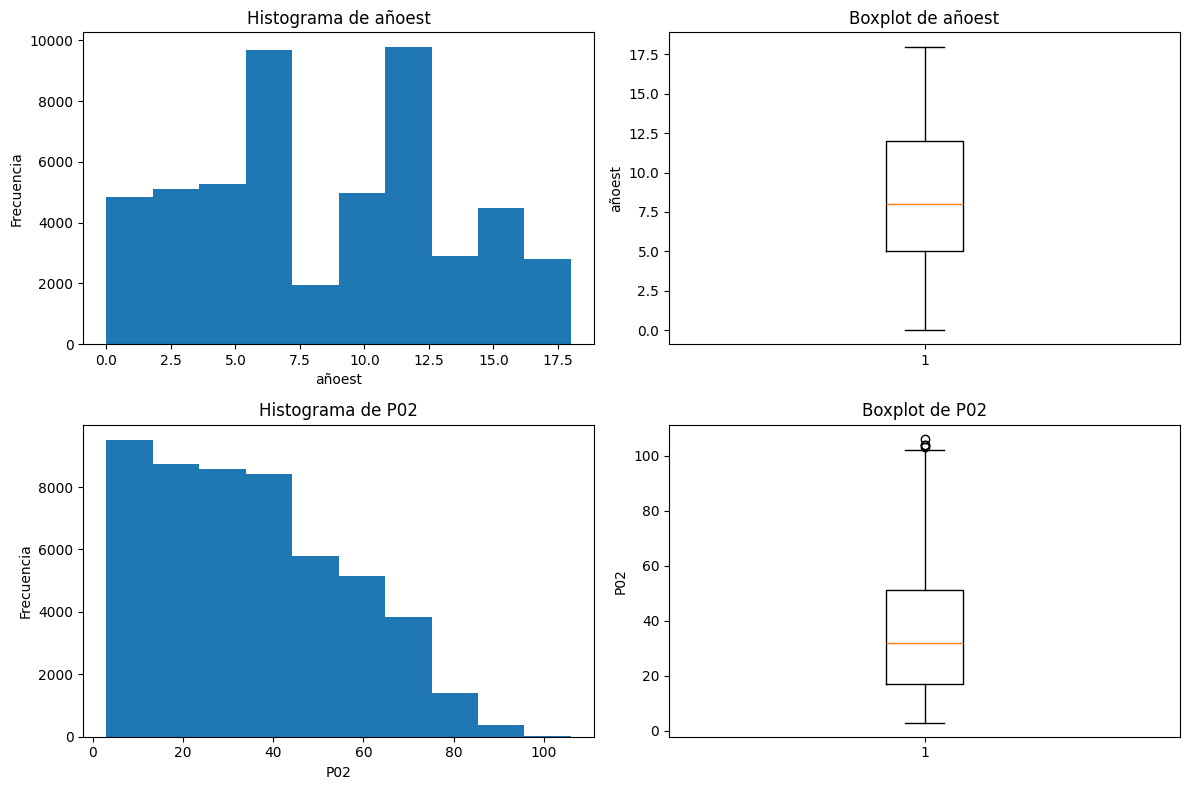

In [16]:
variables=lista_variables
fig, axes = plt.subplots(len(variables), 2, figsize=(12, 4 * len(variables)))
for i, variable in enumerate(variables):
    # Histograma
    axes[i, 0].hist(df_new[variable].dropna())
    axes[i, 0].set_title(f"Histograma de {variable}")
    axes[i, 0].set_xlabel(variable)
    axes[i, 0].set_ylabel("Frecuencia")
    # Boxplot
    axes[i, 1].boxplot(df_new[variable].dropna())
    axes[i, 1].set_title(f"Boxplot de {variable}")
    axes[i, 1].set_ylabel(variable)
plt.tight_layout()
plt.show()

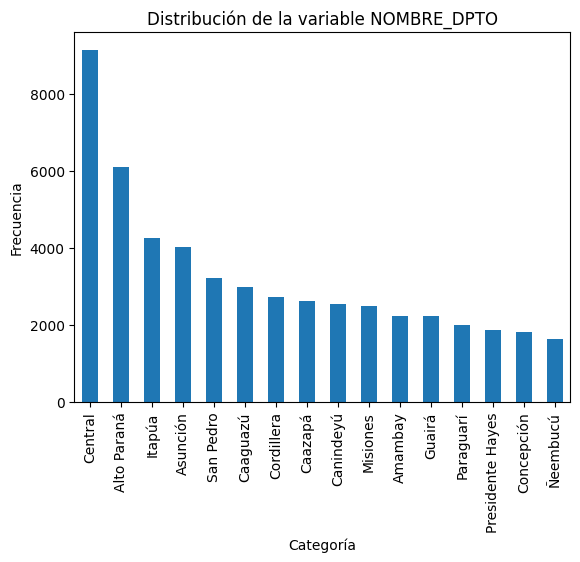

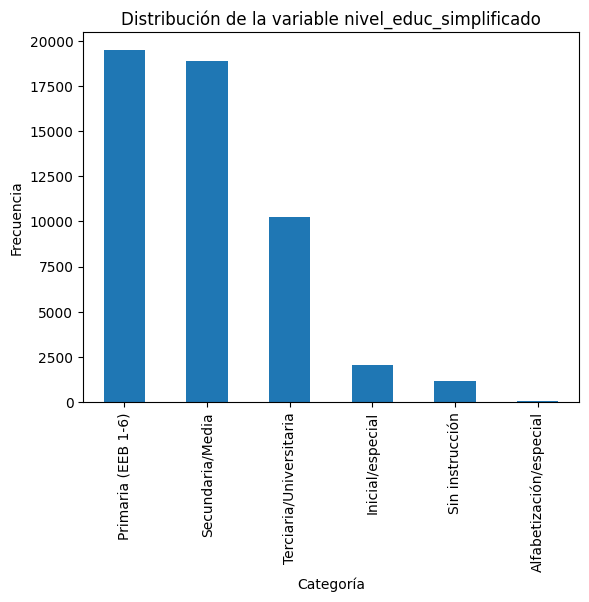

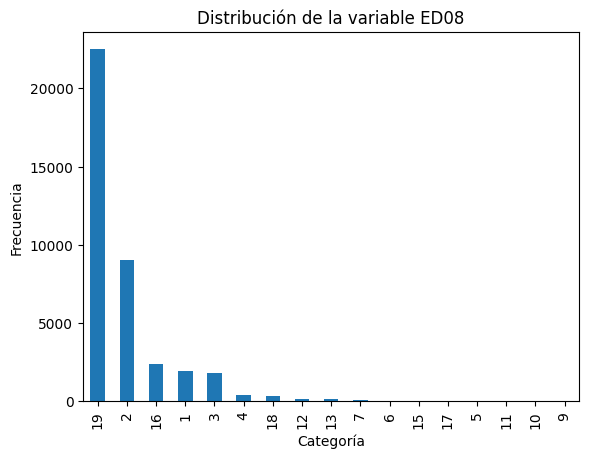

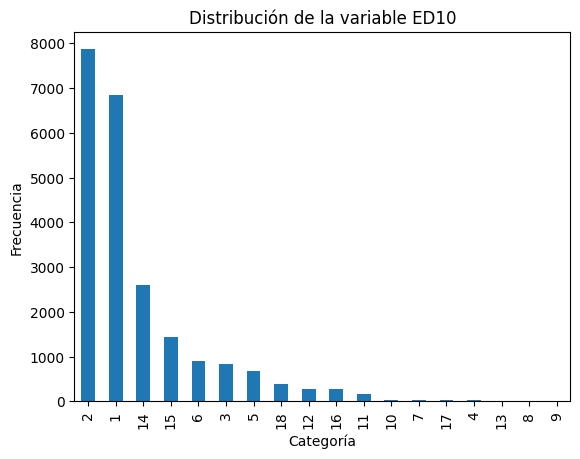

In [17]:
for variable in variables_categoricas:
  df_new[variable].value_counts().plot(kind="bar")
  plt.xlabel("Categoría")
  plt.ylabel("Frecuencia")
  plt.title(f"Distribución de la variable {variable}")
  plt.show()

**Analisis Bivariado**

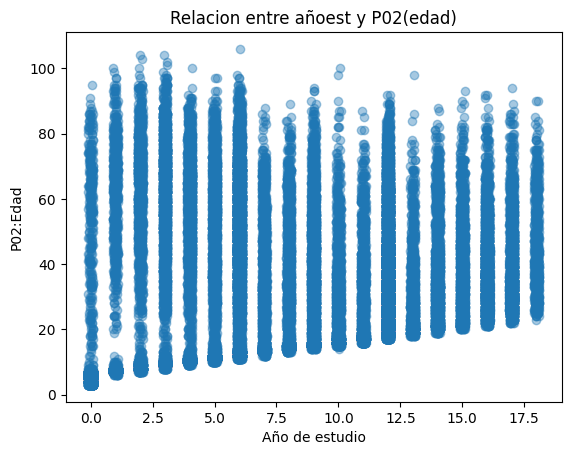

In [18]:
jitter = np.random.uniform(-0.1,0.1,len(df_new['añoest']))
plt.scatter(df_new['añoest']+jitter,df_new['P02'],alpha=0.4)
plt.xlabel("Año de estudio")
plt.ylabel("P02:Edad")
plt.title("Relacion entre añoest y P02(edad)")
plt.show()

In [19]:
#Correlacion de Pearson y spearman
pearson = df_new['P02'].corr(df_new['añoest'],method="pearson")
spearman = df_new['P02'].corr(df_new['añoest'],method="spearman")
print("Correlacion de pearson: ",pearson)
print("Correlacion de spearman: ",spearman)


Correlacion de pearson:  0.10988339468478549
Correlacion de spearman:  0.18011724761291295


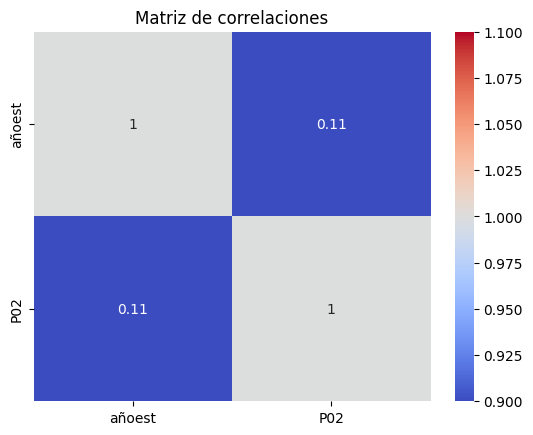

In [20]:
#Mapa de calor

sns.heatmap(df_new[lista_variables].corr(),annot=True,cmap="coolwarm",vmin=1,vmax=1)
plt.title("Matriz de correlaciones")
plt.show()

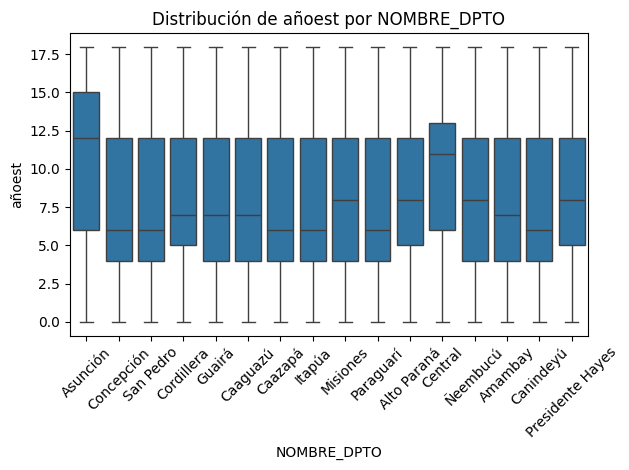

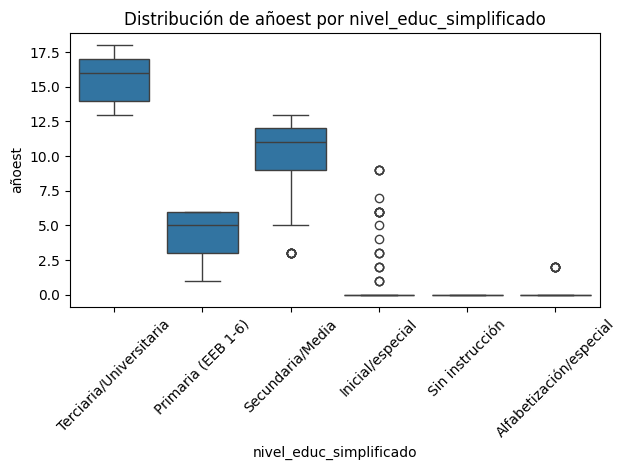

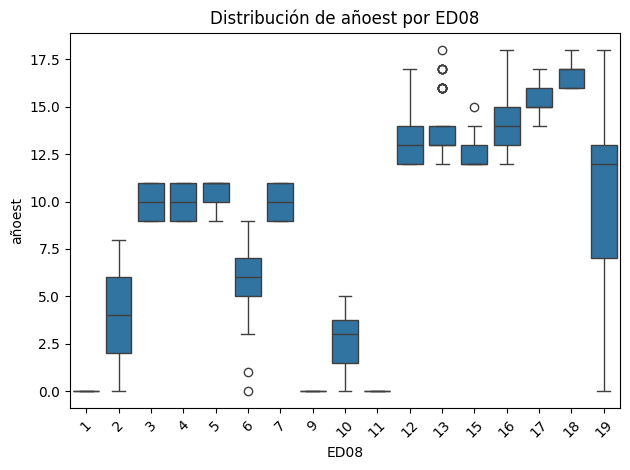

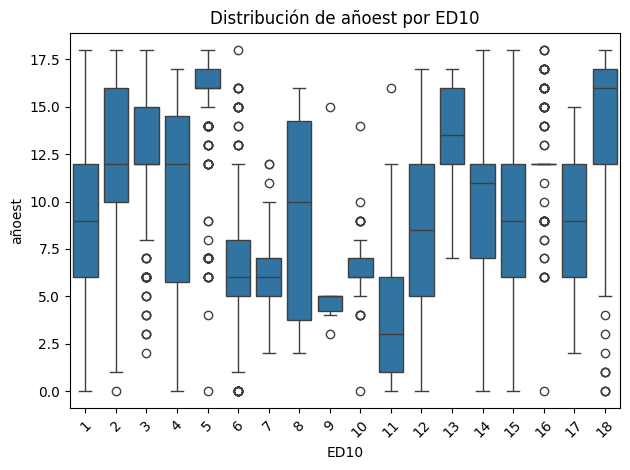

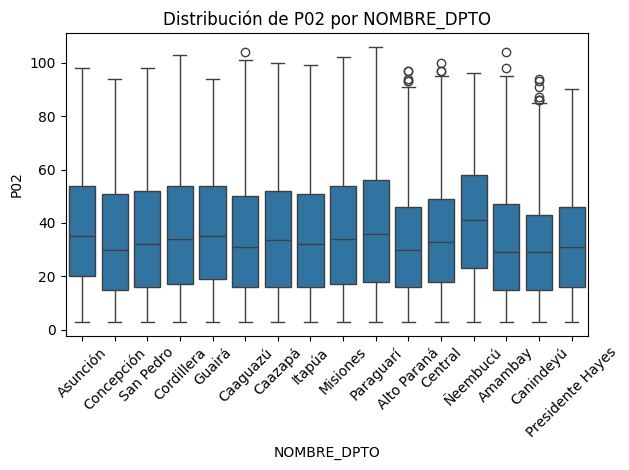

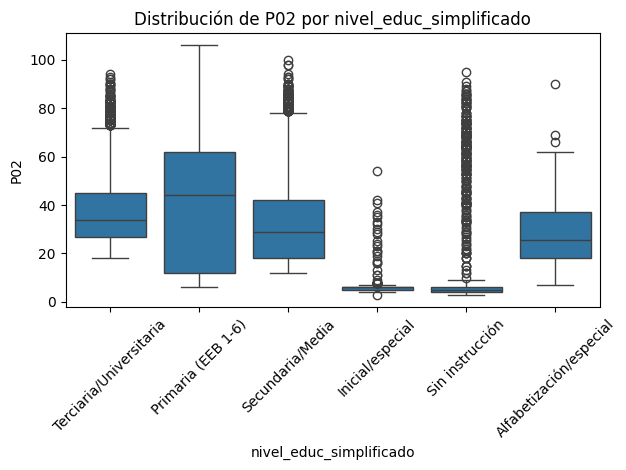

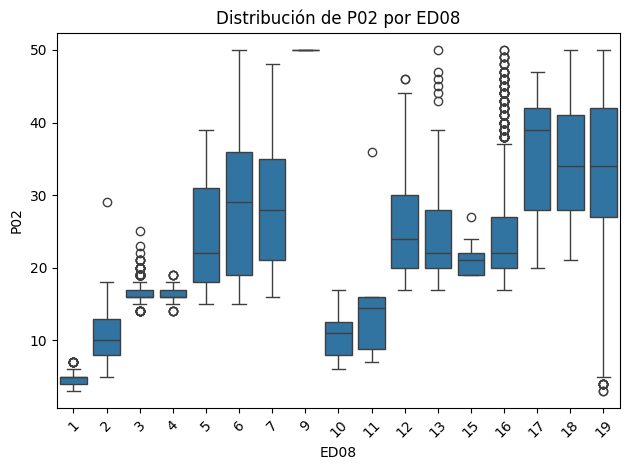

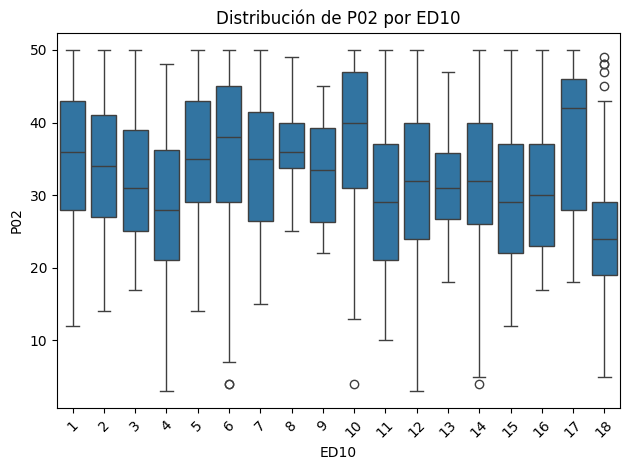

In [21]:
#Categoricas frente a numerica
for numerica in lista_variables:
  for categorica in variables_categoricas:
        sns.boxplot(data=df_new, x=categorica, y=numerica)

        plt.xticks(rotation=45)
        plt.title(f"Distribución de {numerica} por {categorica}")
        plt.tight_layout()
        plt.show()

Categoricas frente a categoricas

In [22]:
for i in range(len(variables_categoricas)-1):
  for j in range(i+1,len(variables_categoricas)):
    print(f"\n\nFrecuencias absolutas de {variables_categoricas[i]} frente {variables_categoricas[j]}:")
    tabla=pd.crosstab(df_new[variables_categoricas[i]],df_new[variables_categoricas[j]])
    print(tabla)



Frecuencias absolutas de NOMBRE_DPTO frente nivel_educ_simplificado:
nivel_educ_simplificado  Alfabetización/especial  Inicial/especial  \
NOMBRE_DPTO                                                          
Alto Paraná                                    4               278   
Amambay                                        5                95   
Asunción                                       4               136   
Caaguazú                                       2               118   
Caazapá                                        1                93   
Canindeyú                                      1               103   
Central                                       11               357   
Concepción                                     2                71   
Cordillera                                     2                97   
Guairá                                         1                80   
Itapúa                                         3               176   
Misiones           

In [23]:
for i in range(len(variables_categoricas)-1):
  for j in range(i+1,len(variables_categoricas)):
    print(f"\n\nFrecuencias absolutas de {variables_categoricas[i]} frente {variables_categoricas[j]}, en cuanto a filas:")
    tabla=pd.crosstab(df_new[variables_categoricas[i]],df_new[variables_categoricas[j]],normalize="index")*100
    print(tabla)



Frecuencias absolutas de NOMBRE_DPTO frente nivel_educ_simplificado, en cuanto a filas:
nivel_educ_simplificado  Alfabetización/especial  Inicial/especial  \
NOMBRE_DPTO                                                          
Alto Paraná                             0.065434          4.547685   
Amambay                                 0.223015          4.237288   
Asunción                                0.099133          3.370508   
Caaguazú                                0.067317          3.971727   
Caazapá                                 0.038314          3.563218   
Canindeyú                               0.039494          4.067930   
Central                                 0.120179          3.900361   
Concepción                              0.109951          3.903244   
Cordillera                              0.073584          3.568801   
Guairá                                  0.044743          3.579418   
Itapúa                                  0.070555          4.139229   


In [24]:
for i in range(len(variables_categoricas)-1):
  for j in range(i+1,len(variables_categoricas)):
    print(f"\n\nFrecuencias absolutas de {variables_categoricas[i]} frente {variables_categoricas[j]}, en cuento a columnas:")
    tabla=pd.crosstab(df_new[variables_categoricas[i]],df_new[variables_categoricas[j]],normalize="columns")*100
    print(tabla)



Frecuencias absolutas de NOMBRE_DPTO frente nivel_educ_simplificado, en cuento a columnas:
nivel_educ_simplificado  Alfabetización/especial  Inicial/especial  \
NOMBRE_DPTO                                                          
Alto Paraná                             9.523810         13.674373   
Amambay                                11.904762          4.672897   
Asunción                                9.523810          6.689621   
Caaguazú                                4.761905          5.804230   
Caazapá                                 2.380952          4.574520   
Canindeyú                               2.380952          5.066404   
Central                                26.190476         17.560256   
Concepción                              4.761905          3.492376   
Cordillera                              4.761905          4.771274   
Guairá                                  2.380952          3.935071   
Itapúa                                  7.142857          8.657157 


**Identificacion de tres anomalias**

Alta concentración de ED08: el 81 % de los registros se concentra en los códigos 19 y 2, destacándose especialmente el 19 con 57,81 %.

Fuerte heterogeneidad territorial del nivel educativo: Asunción y Central presentan una proporción considerablemente mayor de educación terciaria/universitaria que departamentos como Caazapá, San Pedro o Canindeyú.

Relación débil entre edad y años de estudio: Pearson = 0,110 y Spearman = 0,180, indicando que ambas variables tienen una asociación positiva pero de baja intensidad.

1. Fuerte concentración en determinadas respuestas de ED08

La variable ED08, relacionada con la asistencia educativa, presenta una concentración muy marcada:

El código 19 representa 57,81 % de los registros.
El código 2 representa otro 23,23 %.
Por tanto, solo estas dos categorías concentran aproximadamente 81 % de las observaciones.
Además, el código 16 representa 6,15 %, mientras que el resto de categorías tienen frecuencias mucho menores.

Esto constituye un patrón importante porque la distribución de ED08 no es uniforme: unas pocas categorías dominan ampliamente la muestra. El propio análisis univariado del cuaderno señala que los primeros valores concentran cerca del 98 % de los datos.

Un aspecto especialmente relevante es que, según la transformación realizada en el cuaderno, ED08 = 19 significa que la persona no asiste actualmente, mientras que los códigos 1–18 representan diferentes modalidades de asistencia. Por lo tanto, existe una marcada predominancia de personas que no asisten actualmente.

2. Diferencias importantes en el nivel educativo según departamento

El análisis multivariado muestra que el nivel educativo no se distribuye de la misma manera entre los departamentos.

Por ejemplo, en la distribución por filas:

Caazapá: 48,35 % corresponde a Primaria y 29,77 % a Secundaria/Media.
Asunción: solo 20,55 % corresponde a Primaria, mientras que 39,18 % corresponde a Secundaria/Media y 35,39 % a Terciaria/Universitaria.
Central: 27,81 % Primaria, 41,81 % Secundaria/Media y 25,05 % Terciaria/Universitaria.
San Pedro: 45,54 % Primaria y 32,63 % Secundaria/Media.

La diferencia es particularmente visible en el nivel Terciario/Universitario: Asunción presenta 35,39 % y Central 25,05 %, mientras que varios departamentos se encuentran alrededor del 12–17 %.


3. Relación débil entre edad y años de estudio

El análisis multivariado encuentra una correlación positiva, pero débil, entre P02 (edad) y añoest (años de estudio):

Pearson = 0,1099
Spearman = 0,1801

La dirección de la relación es positiva, pero los coeficientes están bastante alejados de 1. Esto indica que la edad por sí sola explica poco la variación de los años de estudio dentro de estos datos.

Es un resultado relevante porque podría esperarse una relación más directa entre edad y años de estudio en determinados grupos de población, pero los datos muestran que la asociación lineal/monótona es relativamente pequeña.
